In [3]:
import yfinance as yf
import pandas as pd
from smooth_graph.portfolio import  Portfolio
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.interpolate import make_smoothing_spline

In [4]:
def get_sgs():

    s_df = yf.download("SPY", start="2005-01-01")["Close"]
    g_df = yf.download("GLD", start="2005-01-01")["Close"]
    spy = s_df["SPY"]

    gld = g_df["GLD"]
    sg  = (spy / gld).dropna()

    usd_conversion = yf.download("GBPUSD=X", start="2005-01-01")["Close"]
    usd_conversion = usd_conversion.reindex(sg.index, method="ffill")
    usd_conversion = usd_conversion.rename(columns={"GBPUSD=X": "GBPUSD"})

    history_data = pd.concat([spy,gld,usd_conversion], axis=1)
    print(history_data.head())
    return sg, history_data

In [5]:
profile = Portfolio(fx_fee_rate=0.0015, initial_balance=1000)

In [6]:
def get_spl(lam, df):
    x = np.arange(len(df))
    y = df.values



    return make_smoothing_spline(x, y, lam=lam)

In [7]:
def get_gradient(spl, df, order=1):

    d_spl = spl.derivative(order)

    x_val = len(df) - 1
    
    return float(d_spl(x_val))

In [8]:
def generate_price_comparison(profile: Portfolio, baseline: Portfolio, df, history_data):
    date = df.index[-1]
    prices = history_data.loc[date]

    spy_price = float(prices["SPY"])

    conversion_rate = prices["GBPUSD"]
    profile.update_conversion(conversion_rate)
    baseline.update_conversion(conversion_rate)

    current_stock = profile.get_current_stock()

    if current_stock is None:
        valuation = profile.get_balance()
        
    elif profile.get_current_stock() == "GLD":
        gld_price = float(prices["GLD"])
        
        valuation = profile.get_portfolio_value("GLD", gld_price)

    else:
        valuation = profile.get_portfolio_value("SPY", spy_price)

    base_valuation = baseline.get_portfolio_value("SPY", spy_price)

    return (valuation, base_valuation)


In [9]:
swap_tomorrow = ""
trade_count = 0

def update_portfolio(profile: Portfolio, gradient, rate_of_gradient, df, history_data, threshold): #threshold should be a float close to 0
    print("Gradient rate:", rate_of_gradient)
    
    date = df.index[-1]

    prices = history_data.loc[date]
    profile.update_conversion(float(prices["GBPUSD"]))
    spy_price = float(prices["SPY"])
    gld_price = float(prices["GLD"])

    global swap_tomorrow
    global trade_count
    if swap_tomorrow == "SPY":
        profile.sell_stock(gld_price, "GLD")
        profile.purchase_stock(spy_price, "SPY")
        swap_tomorrow = ""
        trade_count += 1
    
    elif swap_tomorrow == "GLD":
        profile.sell_stock(spy_price, "SPY")
        profile.purchase_stock(gld_price, "GLD")
        swap_tomorrow = ""
        trade_count += 1

    if abs(gradient) <= threshold:
        if rate_of_gradient > 0:
            # BUY SPY, SELL GLD
            swap_tomorrow = "SPY"
        else:
            # BUY GLD, SELL SPY
            swap_tomorrow = "GLD"

In [10]:
sg_df, history_data = get_sgs()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

                  SPY        GLD    GBPUSD
Date                                      
2005-01-03  80.973518  43.020000  1.904617
2005-01-04  79.984077  42.740002  1.883594
2005-01-05  79.432137  42.669998  1.885512
2005-01-06  79.836006  42.150002  1.876490
2005-01-07  79.721596  41.840000  1.871293


In [11]:

baseline_profile = Portfolio(fx_fee_rate=0.0015, initial_balance=1000)
baseline_profile.update_conversion(float(history_data.head(1)["GBPUSD"].values[0]))
baseline_profile.purchase_stock(stock_price=history_data.head(1)["SPY"].values[0], stock_name="SPY")

In [12]:
profile_valuations = []

for cutoff in range(530,sg_df.shape[0]):
    df = sg_df[:cutoff]

    spl = get_spl(lam=100, df=df)

    gradient = get_gradient(spl, df=df)

    update_portfolio(profile=profile, gradient=gradient, rate_of_gradient=get_gradient(spl=spl, df=df, order=2), df=df, history_data=history_data, threshold=0.0001)

    snapshot = generate_price_comparison(profile=profile, baseline=baseline_profile, df=df, history_data=history_data)
    profile_valuations.append(snapshot)
    print(profile.holdings)
    print(profile.get_balance())

print("No of trades:", trade_count)

Gradient rate: -6.661338147750939e-16
{}
1000
Gradient rate: 1.3322676295501878e-15
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: -6.661338147750939e-16
{}
1000
Gradient rate: 1.3322676295501878e-15
{}
1000
Gradient rate: -1.3322676295501878e-15
{}
1000
Gradient rate: 6.661338147750939e-16
{}
1000
Gradient rate: -6.661338147750939e-16
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: 6.661338147750939e-16
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: -6.661338147750939e-16
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: 6.661338147750939e-16
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: -6.661338147750939e-16
{}
1000
Gradient rate: -6.661338147750939e-16
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: 6.661338147750939e-16
{}
1000
Gradient rate: 6.661338147750939e-16
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: -1.3322676295501878e-15
{}
1000
Gradient rate: 0.0
{}
1000
Gradient rate: 6.661338147750939e-16
{}
100

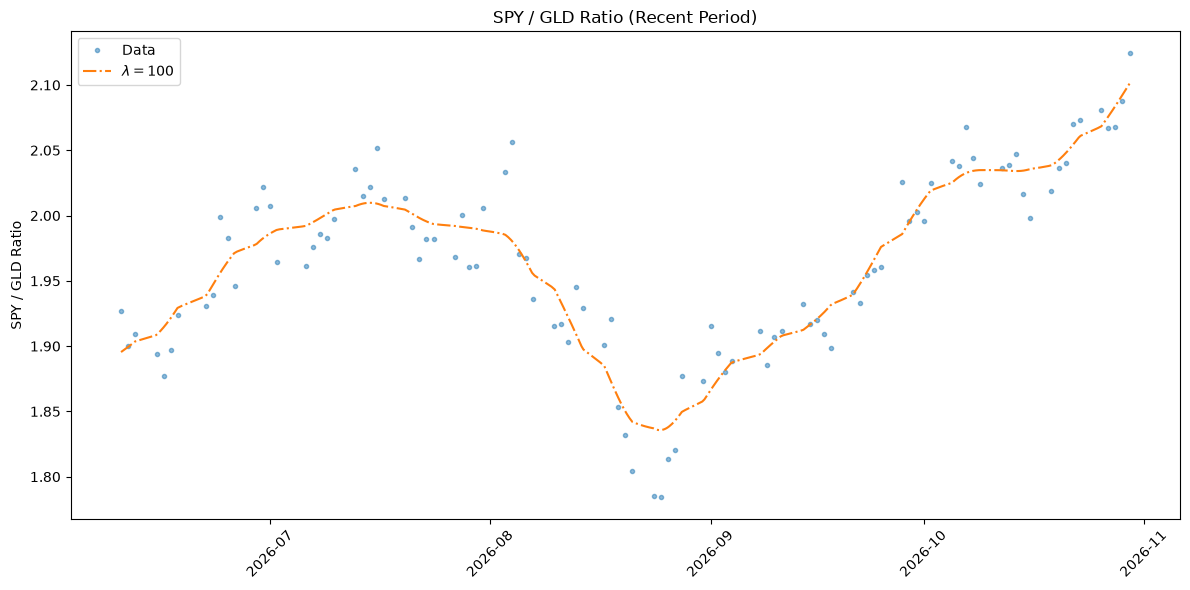

In [18]:
LAM = 100

sg_df_recent = sg_df.tail(100)

x = np.arange(len(sg_df_recent))
y = sg_df_recent.values                      # shape (100,)

# Dense grid for a smooth curve
xnew = np.linspace(x.min(), x.max(), 500)

spl = make_smoothing_spline(x, y, lam=LAM)

# Dates as floats, then interpolate a date for every point on the dense grid
date_nums = mdates.date2num(sg_df_recent.index)
xnew_dates = np.interp(xnew, x, date_nums)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(date_nums, y, 'o', markersize=3, alpha=0.5, label='Data')
ax.plot(xnew_dates, spl(xnew), '-.', label=fr'$\lambda={LAM}$')

ax.xaxis_date()                              # treat the float x-values as dates
ax.tick_params(axis='x', rotation=45)
ax.set_ylabel('SPY / GLD Ratio')
ax.set_title('SPY / GLD Ratio (Recent Period)')
ax.legend()
fig.tight_layout()
plt.show()

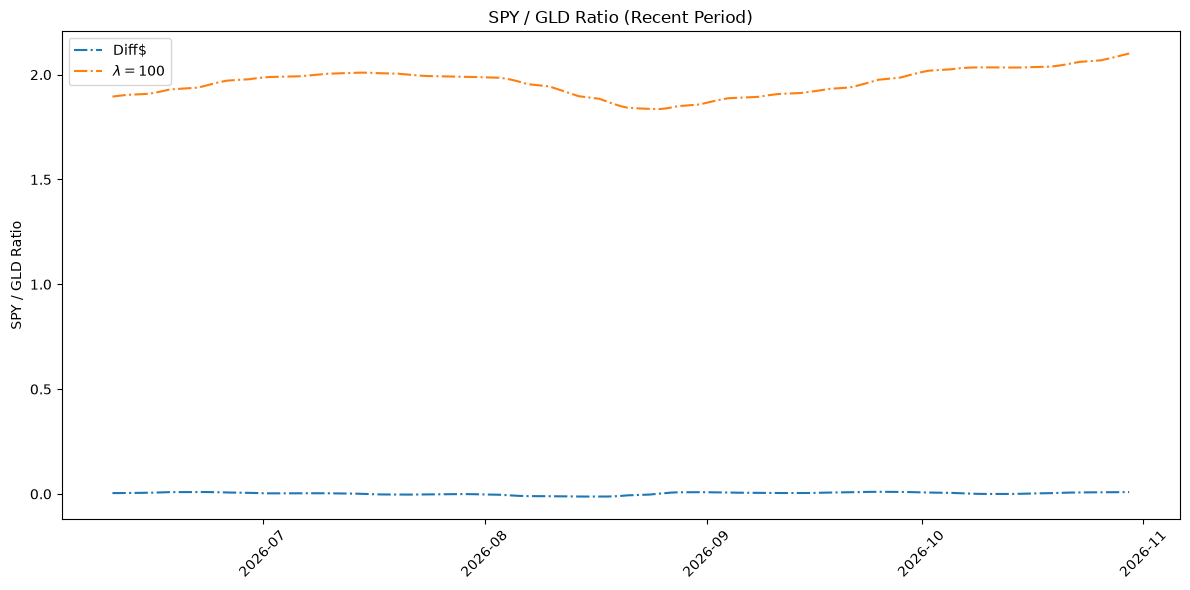

In [19]:
LAM = 100

sg_df_recent = sg_df.tail(100)

x = np.arange(len(sg_df_recent))
y = sg_df_recent.values                      # shape (100,)

# Dense grid for a smooth curve
xnew2 = np.linspace(x.min(), x.max(), 500)

spl2 = make_smoothing_spline(x, y, lam=LAM).derivative()

# Dates as floats, then interpolate a date for every point on the dense grid
date_nums = mdates.date2num(sg_df_recent.index)
xnew_dates2 = np.interp(xnew, x, date_nums)

fig, ax = plt.subplots(figsize=(12, 6))
#ax.plot(date_nums, y, 'o', markersize=3, alpha=0.5, label='Data')
ax.plot(xnew_dates2, spl2(xnew2), '-.', label=fr'Diff$')
ax.plot(xnew_dates, spl(xnew), '-.', label=fr'$\lambda={LAM}$')

ax.xaxis_date()                              # treat the float x-values as dates
ax.tick_params(axis='x', rotation=45)
ax.set_ylabel('SPY / GLD Ratio')
ax.set_title('SPY / GLD Ratio (Recent Period)')
ax.legend()
fig.tight_layout()
plt.show()